# LAB01 — Phân loại Email Rác (Spam Email Classifier)

Notebook trình bày theo thứ tự từ dữ liệu đầu vào, khám phá dữ liệu, tiền xử lý văn bản, TF-IDF, chia tập Train/Test, huấn luyện ba mô hình tự cài đặt và đánh giá trên tập Test.

**Quy ước nhãn trong bộ dữ liệu:** `0 = Ham` (email bình thường), `1 = Spam` (email rác). Các kết quả số liệu trong notebook được tạo từ việc chạy mã trên dữ liệu của dự án, không nhập thủ công.

## 1. Mục tiêu và quy trình thực hiện

Mục tiêu là xây dựng hệ thống dự đoán email thuộc lớp Spam hay Ham dựa trên nội dung văn bản. Notebook sử dụng cấu trúc mã nguồn hiện có của dự án, để mỗi công việc vẫn nằm trong module tương ứng.

Quy trình thực hiện:

1. Đọc và khám phá `data/raw/SpamAssassin.csv`.
2. Làm sạch văn bản, chia dữ liệu theo tỷ lệ 80% Train và 20% Test.
3. Fit TF-IDF **chỉ trên tập Train**, sau đó dùng vectorizer đó chuyển đổi tập Test nhằm hạn chế rò rỉ dữ liệu.
4. Huấn luyện Logistic Regression, Naive Bayes và SVM được cài đặt trong `src/model.py`.
5. Đánh giá trên tập Test bằng Accuracy, Precision, Recall, F1-score, TPR, FPR và Confusion Matrix.

> Ghi chú: các mô hình phân loại trong `src/model.py` được tự cài đặt; thư viện scikit-learn được dùng cho TF-IDF, chia dữ liệu và các chỉ số đánh giá.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Thư mục dự án:", PROJECT_ROOT)

Thư mục dự án: c:\ML\lab01_ML


In [2]:
from pathlib import Path
import sys
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Tìm thư mục gốc để notebook có thể chạy khi mở từ thư mục dự án hoặc notebooks/.
possible_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = None
for path in possible_roots:
    if (path / "data" / "raw" / "SpamAssassin.csv").exists() and (path / "src").is_dir():
        PROJECT_ROOT = path
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục dự án. Hãy mở notebook bên trong thư mục lab01_ML-main."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import eda, preprocess, train, evaluate
from src.preprocess import clean_text

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "SpamAssassin.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

print("Thư mục dự án:", PROJECT_ROOT)
print("Tệp dữ liệu:", DATA_PATH)
print("Đã nạp các module EDA, tiền xử lý, huấn luyện và đánh giá.")

Thư mục dự án: c:\ML\lab01_ML
Tệp dữ liệu: c:\ML\lab01_ML\data\raw\SpamAssassin.csv
Đã nạp các module EDA, tiền xử lý, huấn luyện và đánh giá.


## 2. Đọc và khám phá dữ liệu

Trước tiên, đọc dữ liệu thô để kiểm tra số dòng, số cột, các trường dữ liệu, giá trị thiếu, dòng trùng lặp và phân bố nhãn. Cột `data` chứa nội dung email; cột `label` là nhãn phân loại; `filename` là tên định danh của email.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Kích thước dữ liệu ban đầu: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")
print("Các cột:", df_raw.columns.tolist())
print("\nSố giá trị thiếu theo cột:")
display(df_raw.isnull().sum().to_frame("Số giá trị thiếu"))
print("Số dòng trùng lặp hoàn toàn:", int(df_raw.duplicated().sum()))
print("\nNăm dòng đầu tiên:")
display(df_raw.head())

Kích thước dữ liệu ban đầu: 6,046 dòng × 3 cột
Các cột: ['label', 'data', 'filename']

Số giá trị thiếu theo cột:


,Số giá trị thiếu
label,0
data,0
filename,0


Số dòng trùng lặp hoàn toàn: 0

Năm dòng đầu tiên:


,label,data,filename
0,0,['Subject: Re: New Sequences Window \n Dat...,00001.7c53336b37003a9286aba55d2945844c
1,0,"[""Subject: [zzzzteana] RE: Alexander \nMartin...",00002.9c4069e25e1ef370c078db7ee85ff9ac
2,0,"[""Subject: [zzzzteana] Moscow bomber \nMan Th...",00003.860e3c3cee1b42ead714c5c874fe25f7
3,0,"[""Subject: [IRR] Klez: The Virus That Won't D...",00004.864220c5b6930b209cc287c361c99af1
4,0,"[""Subject: Re: [zzzzteana] Nothing like mama u...",00005.bf27cdeaf0b8c4647ecd61b1d09da613


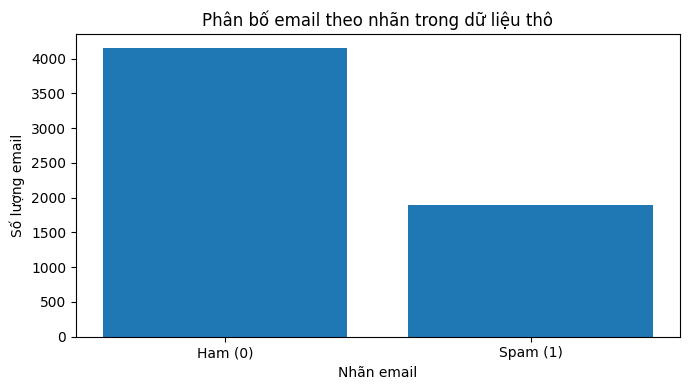

,Nhãn,Số lượng,Tỷ lệ (%)
0,Ham (0),4150,68.64
1,Spam (1),1896,31.36


In [4]:
%matplotlib inline
label_counts = df_raw["label"].value_counts().sort_index()
label_names = {0: "Ham (0)", 1: "Spam (1)"}
plt.figure(figsize=(7, 4))
plt.bar([label_names.get(int(label), str(label)) for label in label_counts.index], label_counts.values)
plt.title("Phân bố email theo nhãn trong dữ liệu thô")
plt.xlabel("Nhãn email")
plt.ylabel("Số lượng email")
plt.tight_layout()
plt.show()
plt.close()

display(pd.DataFrame({
    "Nhãn": [label_names.get(int(label), str(label)) for label in label_counts.index],
    "Số lượng": label_counts.values,
    "Tỷ lệ (%)": (label_counts.values / len(df_raw) * 100).round(2)
}))

### Nhận xét dữ liệu

Biểu đồ và bảng trên cho thấy mức độ cân bằng giữa hai lớp. Việc quan sát phân bố nhãn giúp hiểu đặc điểm dữ liệu trước khi huấn luyện; tuy nhiên, dữ liệu Test vẫn được giữ riêng và không được dùng để học trọng số mô hình.

## 3. Làm sạch văn bản

Hàm `clean_text()` trong `src/preprocess.py` thực hiện các bước chính:

- Chuyển văn bản về chữ thường.
- Loại bỏ thẻ HTML và địa chỉ URL.
- Loại bỏ ký tự không phải chữ cái tiếng Anh và chuẩn hóa khoảng trắng.
- Sau đó, `TfidfVectorizer(stop_words="english")` loại bỏ stop-words tiếng Anh khi tạo đặc trưng.

Ví dụ dưới đây minh họa trước và sau khi làm sạch một đoạn email mẫu.

In [5]:
sample_email = '''<html><body><b>WIN a prize!!!</b> Visit https://example.com now. This is an OFFER.</body></html>'''
print("Trước khi làm sạch:")
print(sample_email)
print("\nSau khi làm sạch:")
print(clean_text(sample_email))

Trước khi làm sạch:
<html><body><b>WIN a prize!!!</b> Visit https://example.com now. This is an OFFER.</body></html>

Sau khi làm sạch:
win a prize visit now this is an offer


## 4. Tiền xử lý, TF-IDF và chia Train/Test

Chạy `src/preprocess.py` để thực hiện toàn bộ quy trình tiền xử lý theo thiết kế của dự án. Các tham số TF-IDF như `max_features` và `ngram_range` được cấu hình trong `config.yaml` để thuận tiện cho việc tinh chỉnh.

Dữ liệu được chia với `test_size=0.2` và `stratify=y`. Trong phiên bản mã nguồn hiện tại, `test_size=0.2` và `random_state=42` được thiết lập trực tiếp trong code, chưa được đọc từ `config.yaml`.

Vectorizer chỉ được `fit_transform()` trên văn bản Train; tập Test chỉ được `transform()` bằng vectorizer đã fit.

Đầu ra gồm `X_train.pkl`, `X_test.pkl`, `y_train.pkl`, `y_test.pkl` trong `data/processed/` và vectorizer tại `models/tfidf_vectorizer.pkl`. Ma trận TF-IDF được lưu dạng thưa để tiết kiệm bộ nhớ.

In [6]:
preprocess.main()

X_train = joblib.load(PROCESSED_DIR / "X_train.pkl")
X_test = joblib.load(PROCESSED_DIR / "X_test.pkl")
y_train = np.asarray(joblib.load(PROCESSED_DIR / "y_train.pkl")).ravel().astype(int)
y_test = np.asarray(joblib.load(PROCESSED_DIR / "y_test.pkl")).ravel().astype(int)

split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Test", "Tổng"],
    "Số mẫu": [len(y_train), len(y_test), len(y_train) + len(y_test)],
    "Tỷ lệ (%)": [len(y_train) / (len(y_train) + len(y_test)) * 100,
                  len(y_test) / (len(y_train) + len(y_test)) * 100, 100.0]
})
display(split_summary.round(2))
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test :", X_test.shape)
print("Số đặc trưng TF-IDF:", X_train.shape[1])
print("Số nhãn Train (0=Ham, 1=Spam):", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Số nhãn Test  (0=Ham, 1=Spam):", pd.Series(y_test).value_counts().sort_index().to_dict())

Da tien xu ly xong.
So mau train: 4736
So mau test: 1184
So dac trung TF-IDF: 10000
Test size: 0.2
Random state: 42
Max features: 10000
N-gram range: (1, 2)
Da luu 4 tap du lieu dang .pkl trong data/processed/
Da luu TF-IDF trong models/tfidf_vectorizer.pkl


,Tập dữ liệu,Số mẫu,Tỷ lệ (%)
0,Train,4736,80.0
1,Test,1184,20.0
2,Tổng,5920,100.0


Kích thước X_train: (4736, 10000)
Kích thước X_test : (1184, 10000)
Số đặc trưng TF-IDF: 10000
Số nhãn Train (0=Ham, 1=Spam): {0: 3288, 1: 1448}
Số nhãn Test  (0=Ham, 1=Spam): {0: 822, 1: 362}


### Vì sao cần tách Train/Test trước khi fit TF-IDF?

Nếu TF-IDF được fit trên toàn bộ dữ liệu, thông tin từ tập Test có thể ảnh hưởng đến quá trình xây dựng từ vựng và trọng số đặc trưng. Dự án chia dữ liệu trước, chỉ fit vectorizer trên Train, vì vậy tập Test được dùng để đánh giá sau huấn luyện chứ không dùng để học mô hình.

## 5. Huấn luyện ba mô hình

Các mô hình được cài đặt thủ công trong `src/model.py`:

- **Logistic Regression:** cập nhật trọng số bằng Gradient Descent và hàm sigmoid.
- **Naive Bayes:** ước lượng xác suất tiên nghiệm, trung bình và phương sai đặc trưng theo lớp; dự đoán dựa trên log-xác suất.
- **SVM:** cập nhật trọng số theo hàm mất mát hinge và hệ số điều chuẩn.

Hàm `train.main()` chỉ nạp `X_train` và `y_train`, không nạp tập Test. Sau khi huấn luyện, từng mô hình được lưu riêng trong thư mục `models/`.

In [7]:
train.main()

model_paths = [
    MODEL_DIR / "model_lr.pkl",
    MODEL_DIR / "model_nb.pkl",
    MODEL_DIR / "model_svm.pkl",
]
print("\nKiểm tra các tệp mô hình:")
for path in model_paths:
    print(f"{'Có' if path.exists() else 'Thiếu'}: {path.relative_to(PROJECT_ROOT)}")

[INFO] Đang tải dữ liệu huấn luyện...
[INFO] Tải thành công! X_train: (4736, 10000), y_train: (4736,)

BẮT ĐẦU HUẤN LUYỆN 3 MÔ HÌNH (FROM SCRATCH)

[TRAIN] Đang huấn luyện mô hình: Logistic Regression...
[DONE] Hoàn thành Logistic Regression trong 32.63 giây.
[SAVE] Đã lưu mô hình tại: C:\ML\lab01_ML\models\model_lr.pkl

[TRAIN] Đang huấn luyện mô hình: Naive Bayes...
[DONE] Hoàn thành Naive Bayes trong 0.20 giây.
[SAVE] Đã lưu mô hình tại: C:\ML\lab01_ML\models\model_nb.pkl

[TRAIN] Đang huấn luyện mô hình: SVM...
[DONE] Hoàn thành SVM trong 8.00 giây.
[SAVE] Đã lưu mô hình tại: C:\ML\lab01_ML\models\model_svm.pkl
[LOG] Đã lưu lịch sử thực nghiệm tại: C:\ML\lab01_ML\docs\experiment_logs.csv

HOÀN TẤT QUÁ TRÌNH HUẤN LUYỆN VÀ LƯU MÔ HÌNH!
Tổng thời gian huấn luyện: 40.83 giây

Kiểm tra các tệp mô hình:
Có: models\model_lr.pkl
Có: models\model_nb.pkl
Có: models\model_svm.pkl


## 6. Đánh giá mô hình trên tập Train và tập Test

Notebook dùng tập `X_train`, `y_train` và tập `X_test`, `y_test` đã được lưu ở bước tiền xử lý để tính các chỉ số:

- **Accuracy:** tỷ lệ dự đoán đúng trên tổng số email.
- **Precision:** trong các email được dự đoán là Spam, tỷ lệ thực sự là Spam.
- **Recall:** trong các email Spam thực tế, tỷ lệ được phát hiện đúng.
- **F1-score:** trung bình điều hòa của Precision và Recall.
- **TPR:** tỷ lệ Spam thực tế được phát hiện đúng, bằng `TP / (TP + FN)`.
- **FPR:** tỷ lệ email Ham bị dự đoán nhầm là Spam, bằng `FP / (FP + TN)`.

Với quy ước `Spam = 1`, Confusion Matrix được đọc theo thứ tự nhãn `[0, 1]`: hàng là nhãn thực tế, cột là nhãn dự đoán.

In [8]:
evaluate.main()

results = pd.read_csv(
    PROJECT_ROOT / "reports" / "metrics_summary.csv",
    encoding="utf-8-sig"
)

metrics_columns = [
    "Mô hình",
    "Tập dữ liệu",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "TPR",
    "FPR",
    "TN",
    "FP",
    "FN",
    "TP"
]

missing_columns = [
    col for col in metrics_columns
    if col not in results.columns
]

if missing_columns:
    print("Các cột hiện có:", results.columns.tolist())
    raise ValueError(
        f"File CSV thiếu các cột: {missing_columns}"
    )

model_order = {
    "Logistic Regression": 0,
    "Naive Bayes": 1,
    "SVM": 2
}

dataset_order = {
    "Train": 0,
    "Test": 1
}

results["_model_order"] = (
    results["Mô hình"].map(model_order).fillna(99)
)

results["_dataset_order"] = (
    results["Tập dữ liệu"].map(dataset_order).fillna(99)
)

results = results.sort_values(
    ["_model_order", "_dataset_order"]
)

results = results[metrics_columns].reset_index(drop=True)

display(results.round(4))


BẮT ĐẦU ĐÁNH GIÁ CÁC MÔ HÌNH
[INFO] Đang tải dữ liệu Train và Test...
[INFO] X_train: (4736, 10000), y_train: (4736,)
[INFO] X_test: (1184, 10000), y_test: (1184,)
[INFO] Đang tải các mô hình...

[INFO] Đang đánh giá Logistic Regression trên tập Train...
Train | Accuracy: 0.9535 | Precision: 0.9008 | Recall: 0.9530 | F1: 0.9262 | TPR: 0.9530 | FPR: 0.0462

[INFO] Đang đánh giá Logistic Regression trên tập Test...
Test | Accuracy: 0.9316 | Precision: 0.8469 | Recall: 0.9475 | F1: 0.8944 | TPR: 0.9475 | FPR: 0.0754
[DONE] Đã lưu confusion matrix tại: C:\ML\lab01_ML\docs\images\confusion_matrix_lr.png

[INFO] Đang đánh giá Naive Bayes trên tập Train...
Train | Accuracy: 0.9962 | Precision: 0.9897 | Recall: 0.9979 | F1: 0.9938 | TPR: 0.9979 | FPR: 0.0046

[INFO] Đang đánh giá Naive Bayes trên tập Test...
Test | Accuracy: 0.9730 | Precision: 0.9635 | Recall: 0.9475 | F1: 0.9554 | TPR: 0.9475 | FPR: 0.0158
[DONE] Đã lưu confusion matrix tại: C:\ML\lab01_ML\docs\images\confusion_matrix_nb.pn

,Mô hình,Tập dữ liệu,Accuracy,Precision,Recall,F1,TPR,FPR,TN,FP,FN,TP
0,Logistic Regression,Train,0.9535,0.9008,0.9530,0.9262,0.9530,0.0462,3136,152,68,1380
1,Logistic Regression,Test,0.9316,0.8469,0.9475,0.8944,0.9475,0.0754,760,62,19,343
2,Naive Bayes,Train,0.9962,0.9897,0.9979,0.9938,0.9979,0.0046,3273,15,3,1445
3,Naive Bayes,Test,0.9730,0.9635,0.9475,0.9554,0.9475,0.0158,809,13,19,343
4,SVM,Train,0.7194,0.8889,0.0939,0.1699,0.0939,0.0052,3271,17,1312,136
5,SVM,Test,0.7188,0.8919,0.0912,0.1654,0.0912,0.0049,818,4,329,33


## 7. Ma trận nhầm lẫn (Confusion Matrix)

Mỗi ma trận cho biết số email Ham/Spam được dự đoán đúng và số email bị nhầm. Các hình được lưu vào `docs/images/` để có thể sử dụng trong báo cáo tổng kết.

Logistic Regression


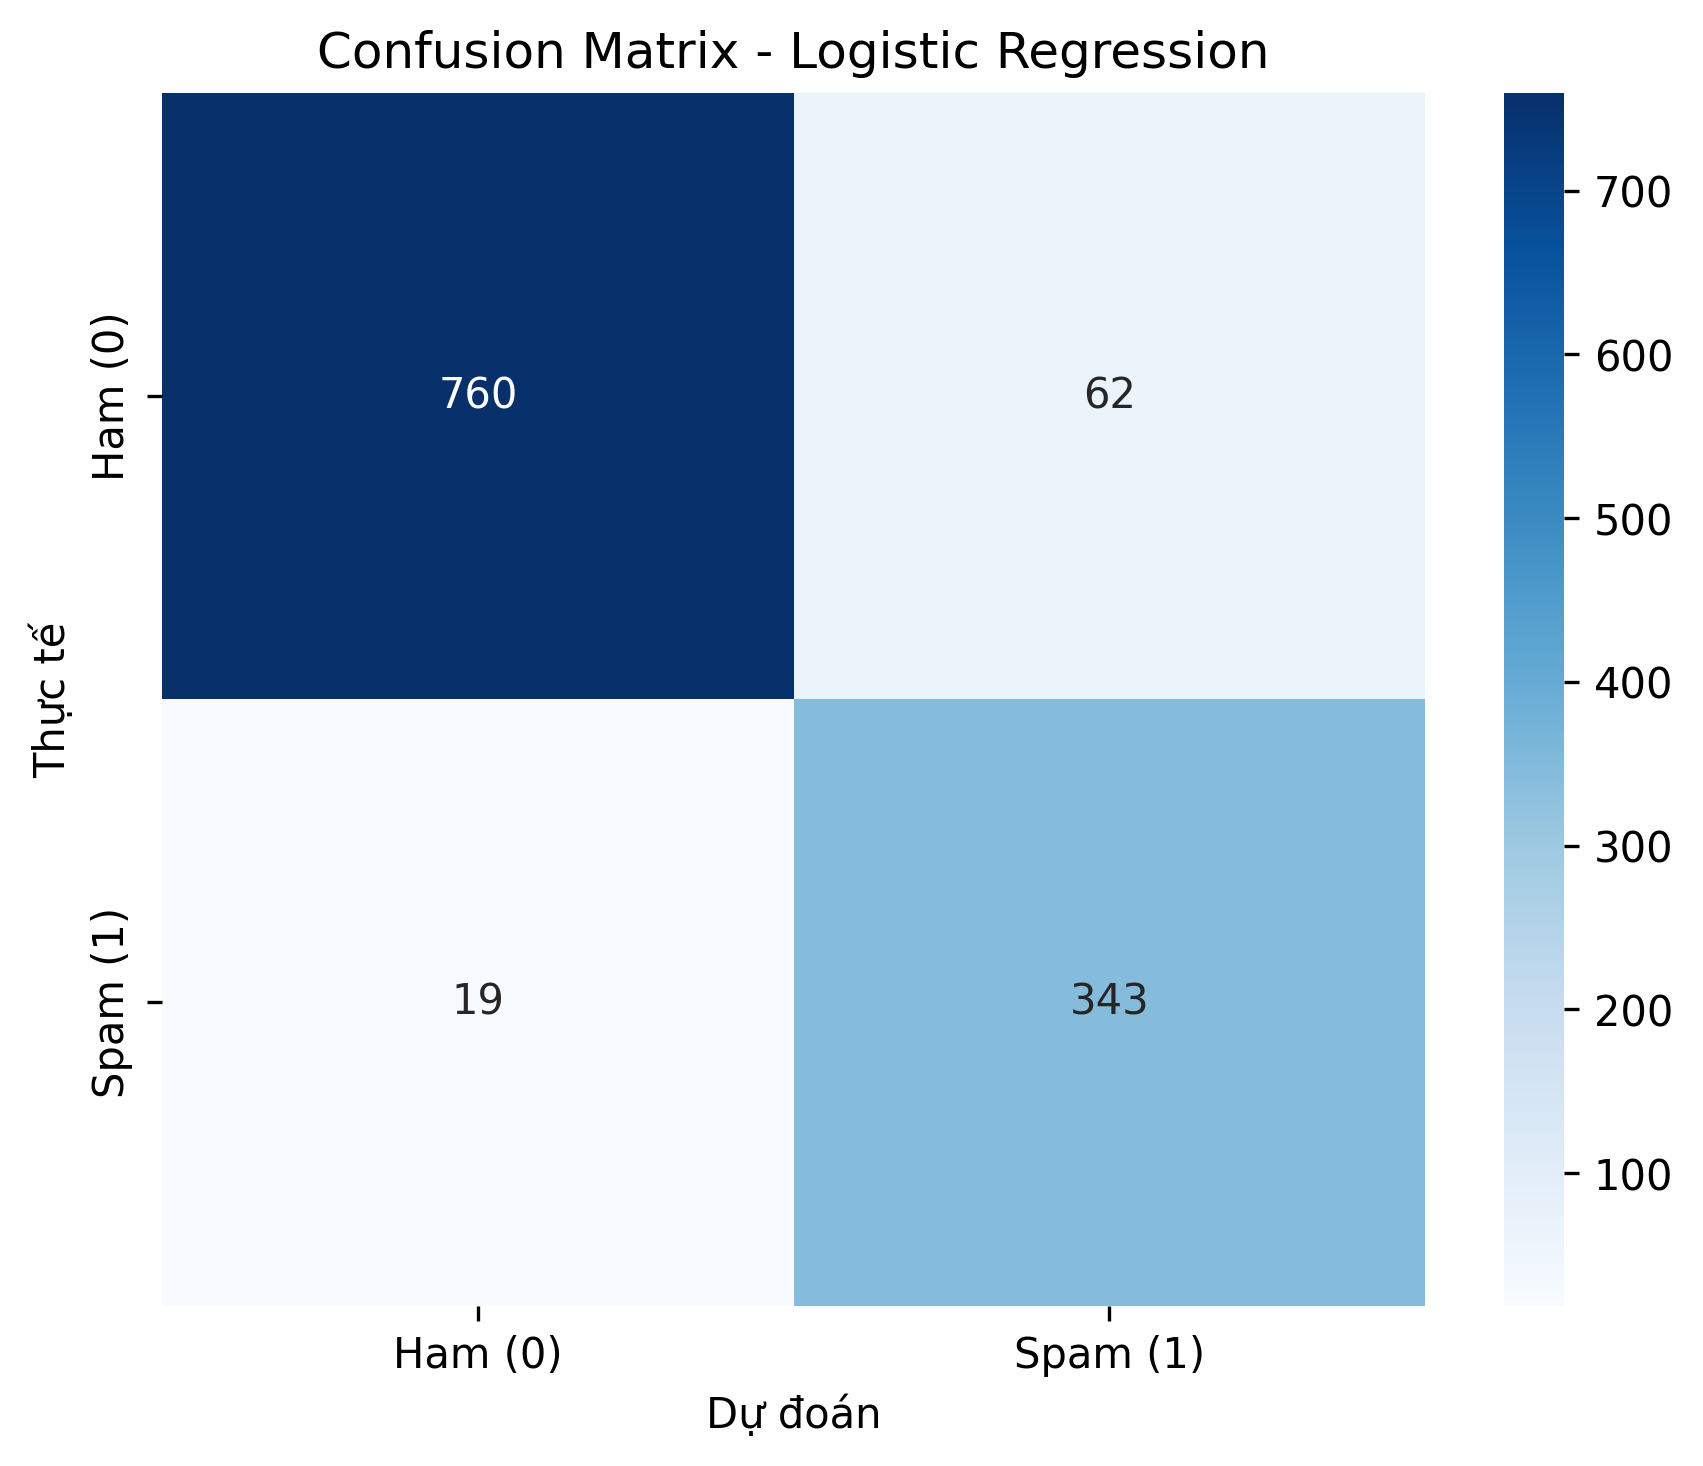

Naive Bayes


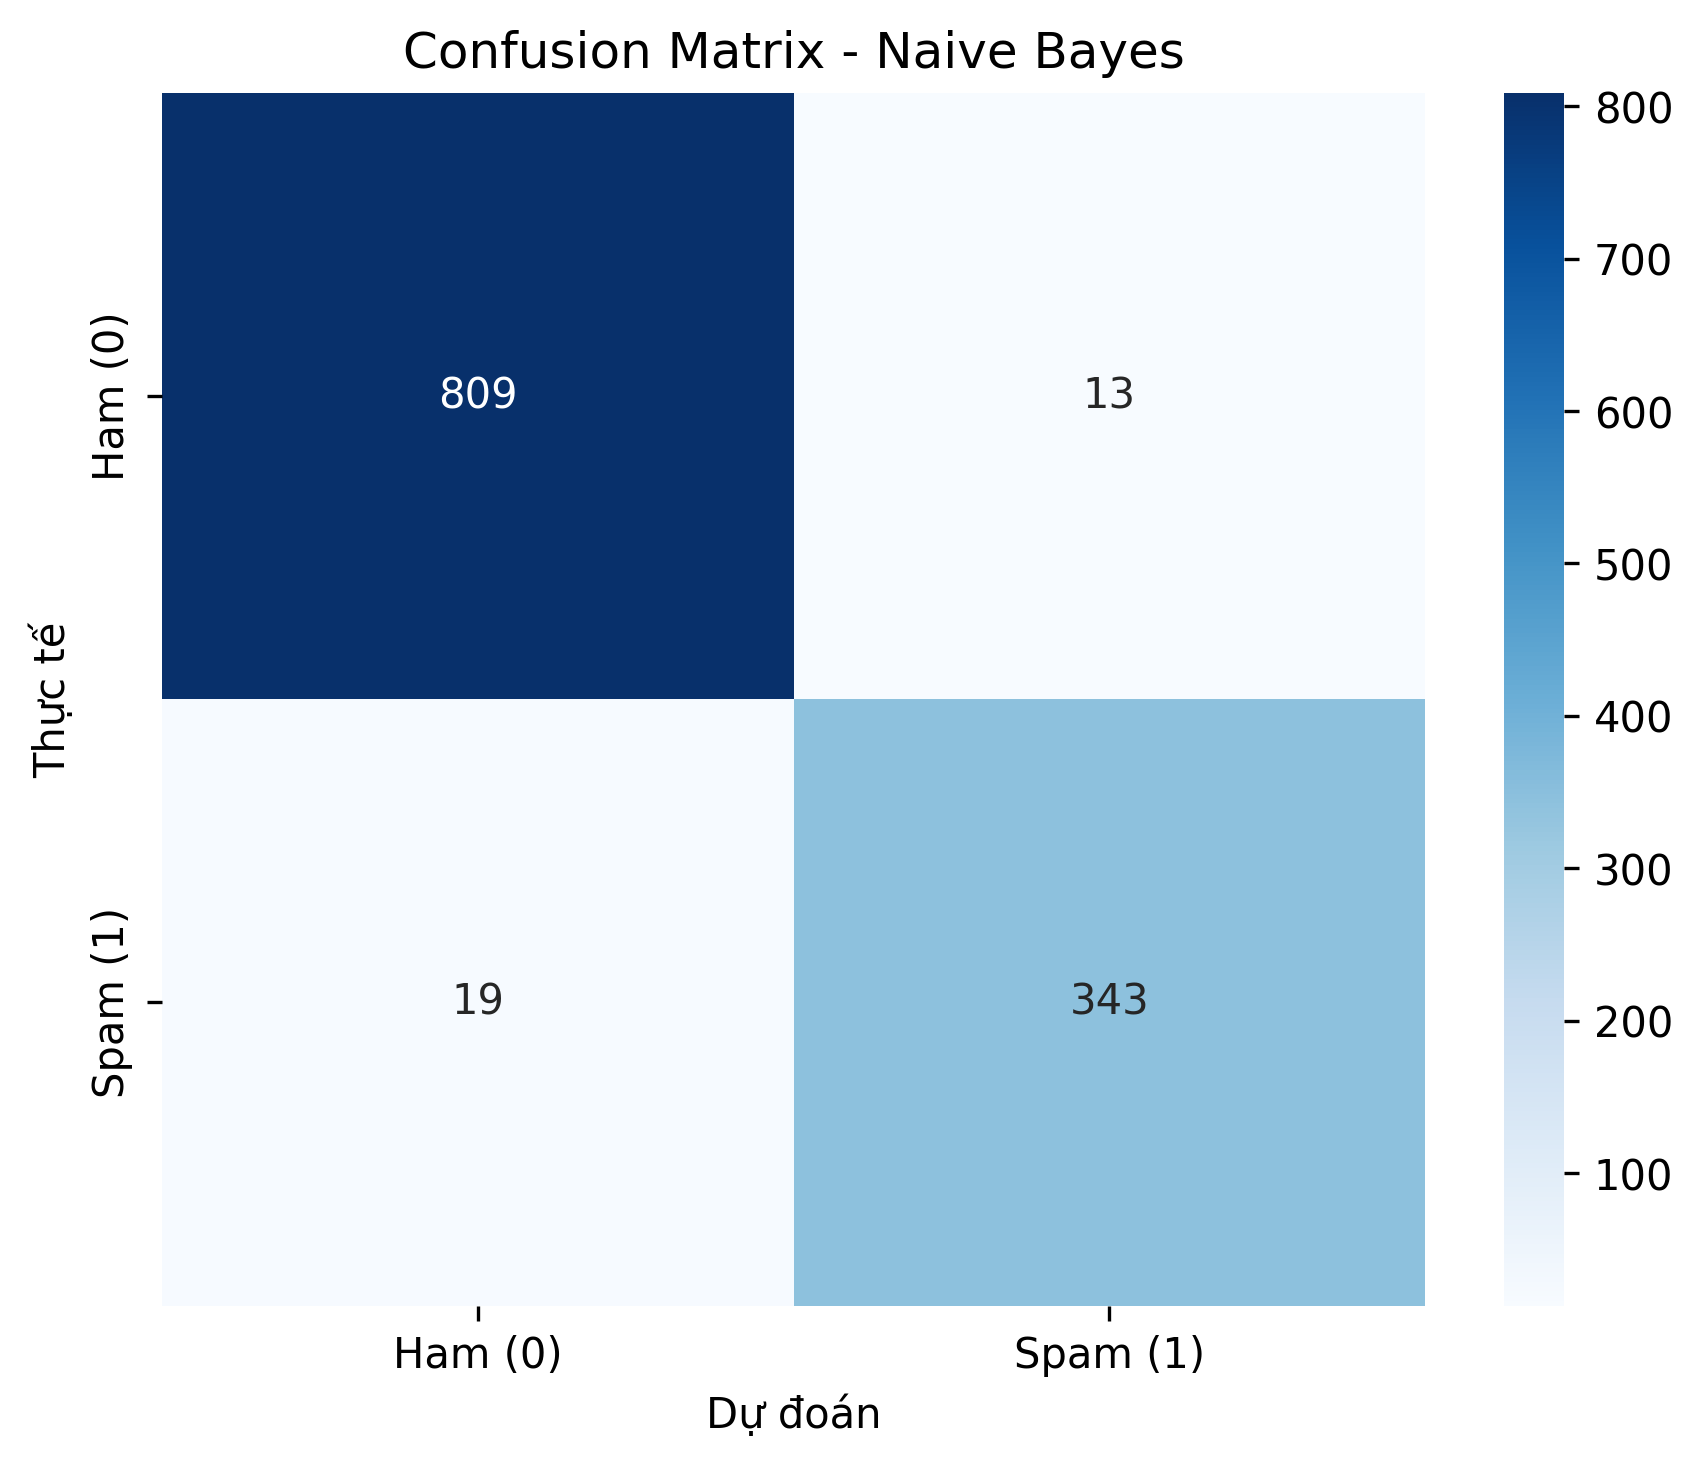

SVM


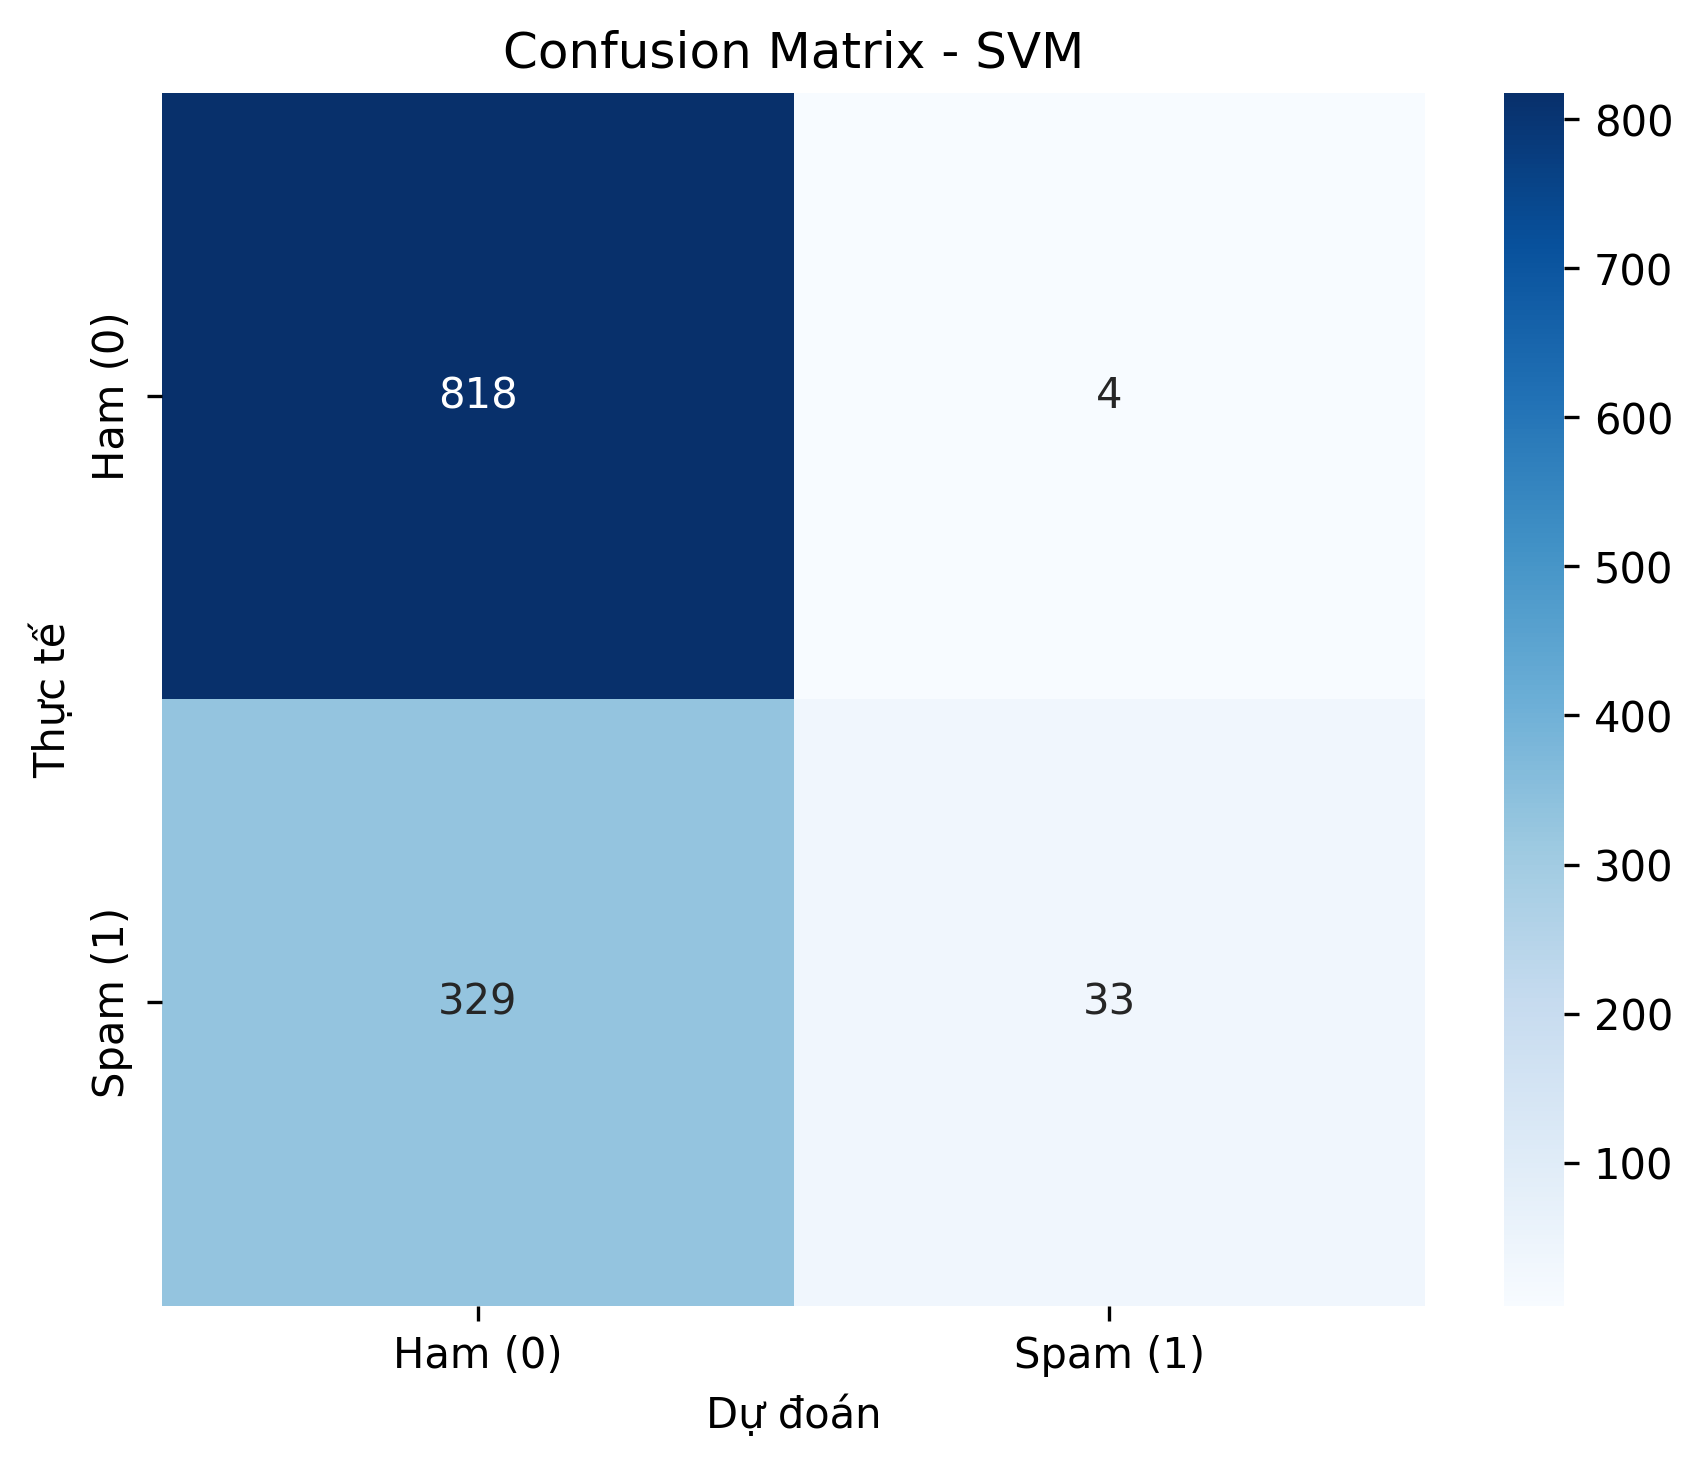

In [9]:
IMAGE_DIR = PROJECT_ROOT / "docs" / "images"
confusion_images = [
    ("Logistic Regression", IMAGE_DIR / "confusion_matrix_lr.png"),
    ("Naive Bayes", IMAGE_DIR / "confusion_matrix_nb.png"),
    ("SVM", IMAGE_DIR / "confusion_matrix_svm.png"),
]

for title, image_path in confusion_images:
    print(title)

    if image_path.exists():
        img = Image(filename=str(image_path))
        display(img)
    else:
        print("Chưa tìm thấy hình:", image_path)


## 8. So sánh và nhận xét kết quả

Bảng dưới đây được sắp xếp theo F1-score giảm dần. F1-score giúp cân bằng Precision và Recall, phù hợp khi cần xem xét đồng thời khả năng phát hiện Spam và hạn chế dự đoán nhầm.

In [10]:

comparison = results.sort_values(
    ["Tập dữ liệu", "F1"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    comparison[
        [
            "Mô hình",
            "Tập dữ liệu",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "TPR",
            "FPR"
        ]
    ].round(4)
)

for dataset in ["Train", "Test"]:
    subset = comparison[
        comparison["Tập dữ liệu"] == dataset
    ]

    best_f1 = subset.loc[subset["F1"].idxmax()]
    lowest_fpr = subset.loc[subset["FPR"].idxmin()]

    print(f"\nKết quả trên tập {dataset}:")
    print(
        f"Mô hình có F1-score cao nhất: "
        f"{best_f1['Mô hình']} ({best_f1['F1']:.4f})."
    )
    print(
        f"Mô hình có FPR thấp nhất: "
        f"{lowest_fpr['Mô hình']} ({lowest_fpr['FPR']:.4f})."
    )


,Mô hình,Tập dữ liệu,Accuracy,Precision,Recall,F1,TPR,FPR
0,Naive Bayes,Test,0.9730,0.9635,0.9475,0.9554,0.9475,0.0158
1,Logistic Regression,Test,0.9316,0.8469,0.9475,0.8944,0.9475,0.0754
2,SVM,Test,0.7188,0.8919,0.0912,0.1654,0.0912,0.0049
3,Naive Bayes,Train,0.9962,0.9897,0.9979,0.9938,0.9979,0.0046
4,Logistic Regression,Train,0.9535,0.9008,0.9530,0.9262,0.9530,0.0462
5,SVM,Train,0.7194,0.8889,0.0939,0.1699,0.0939,0.0052



Kết quả trên tập Train:
Mô hình có F1-score cao nhất: Naive Bayes (0.9938).
Mô hình có FPR thấp nhất: Naive Bayes (0.0046).

Kết quả trên tập Test:
Mô hình có F1-score cao nhất: Naive Bayes (0.9554).
Mô hình có FPR thấp nhất: SVM (0.0049).


## 9. Thử dự đoán một email mới

Ví dụ này minh họa cách sử dụng vectorizer đã lưu và một mô hình đã huấn luyện để phân loại nội dung email mới. Đây chỉ là ví dụ minh họa; không thay thế cho đánh giá mô hình trên toàn bộ tập Test.

In [11]:
vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.pkl")
model_lr = joblib.load(MODEL_DIR / "model_lr.pkl")

new_email = "Congratulations! You have won a free prize. Click here to claim your offer now."

cleaned_email = clean_text(new_email)

new_email_vector = vectorizer.transform([cleaned_email])
new_email_vector = new_email_vector.toarray()

predicted_label = int(model_lr.predict(new_email_vector)[0])

predicted_name = "Spam (email rác)" if predicted_label == 1 else "Ham (email bình thường)"

print("Email thử nghiệm:", new_email)
print("Nội dung sau làm sạch:", cleaned_email)
print("Dự đoán Logistic Regression:", predicted_name)

Email thử nghiệm: Congratulations! You have won a free prize. Click here to claim your offer now.
Nội dung sau làm sạch: congratulations you have won a free prize click here to claim your offer now
Dự đoán Logistic Regression: Spam (email rác)


## 10. Kết luận

Notebook đã thực hiện phân loại email Spam và Ham bằng TF-IDF, chia dữ liệu Train/Test theo tỷ lệ 80/20 và đánh giá ba mô hình Logistic Regression, Naive Bayes và SVM.

Kết quả cho thấy **Naive Bayes tốt nhất** với Accuracy 0.9730 và F1-score 0.9554. Logistic Regression đạt Accuracy 0.9316, còn SVM đạt Accuracy 0.7188 và bỏ sót nhiều email Spam.

Nhìn chung, **Naive Bayes là mô hình phù hợp nhất trong lần thực nghiệm này**. Cần chạy Run All để kiểm tra lại kết quả và bảo đảm số liệu thống nhất.